# TP — Modèles génératifs avec PyTorch
Première partie : classification, autoencodeur et VAE.




In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)
from pathlib import Path
torch.manual_seed(42)
np.random.seed(42)
CAPTURES = Path("captures")
CAPTURES.mkdir(exist_ok=True)
def afficher(nom):
    plt.savefig(CAPTURES / nom, dpi=140, bbox_inches="tight")
    plt.show()

PyTorch : 2.14.1+cpu
Device : cpu


## 1. Chargement de MNIST
MNIST contient 60 000 images d’entraînement et 10 000 images de test. Chaque image est un chiffre de 28 × 28 pixels. `ToTensor` transforme les pixels en valeurs entre 0 et 1. Les lots contiennent 128 images.

In [3]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

Train : 60000
Test  : 10000


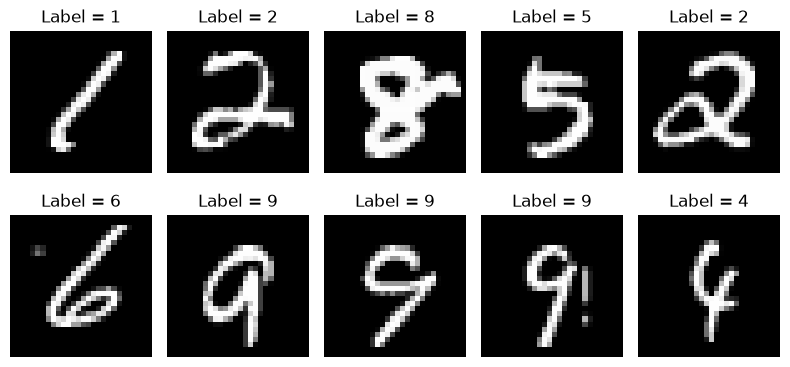

In [4]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
afficher("01_mnist.png")

## 2. Modèle discriminatif
Le réseau transforme les 784 pixels en 128 caractéristiques puis en 10 scores. ReLU introduit une non-linéarité. CrossEntropyLoss compare les scores avec les labels. Adam ajuste les poids.

In [5]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

In [7]:
def train_classifier(model, loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3 - Loss = 0.4115
Epoch 2/3 - Loss = 0.1943
Epoch 3/3 - Loss = 0.1374


In [8]:
def evaluate_classifier(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total

accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100*accuracy:.2f}%")

Accuracy = 96.37%


In [9]:
from torcheval.metrics import MulticlassAccuracy

@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    device = next(model.parameters()).device

    metric = MulticlassAccuracy(device=device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        metric.update(logits, y)

    return metric.compute().item()


accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100 * accuracy:.2f}%")

c:\IA Générative Multi Modale\tp2\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Accuracy = 96.37%


L’accuracy mesure la proportion de bonnes prédictions. Les deux méthodes calculent la même mesure. Le classifieur reconnaît les chiffres mais ne génère pas d’images.

## 3. Autoencodeur simple
L’encodeur compresse une image en deux valeurs latentes. Le décodeur reconstruit les 784 pixels. Les labels ne sont pas utilisés durant l’entraînement. La MSE mesure l’écart entre les pixels originaux et reconstruits.

In [10]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

ae = Autoencoder(latent_dim=2).to(device)
ae

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [11]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
def train_autoencoder(model, loader, epochs=5):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.0650
Epoch 2/5 - Loss = 0.0515
Epoch 3/5 - Loss = 0.0476
Epoch 4/5 - Loss = 0.0453
Epoch 5/5 - Loss = 0.0441


In [12]:
@torch.no_grad()
def evaluer_ae(model, loader):
    model.eval()
    erreur, n = 0., 0
    for x, _ in loader:
        x = x.to(device)
        erreur += F.mse_loss(model(x), x, reduction="sum").item()
        n += x.numel()
    return erreur / n

print(f"MSE test : {evaluer_ae(ae, test_loader):.4f}")

MSE test : 0.0435


### Reconstruction et exploration
On compare les images originales aux reconstructions, puis on représente chaque image de test par un point en 2D. Les couleurs correspondent aux classes réelles, uniquement pour la visualisation.

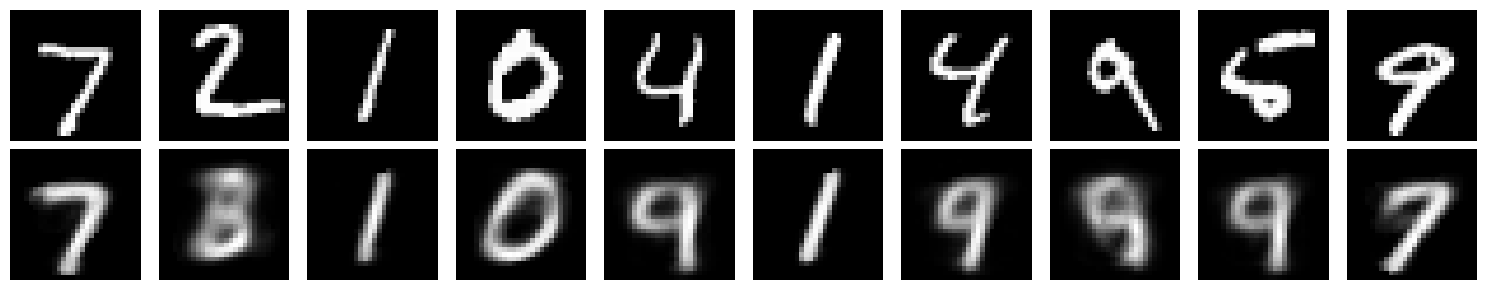

In [13]:
ae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat = ae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")

plt.tight_layout()
afficher("02_ae_reconstruction.png")

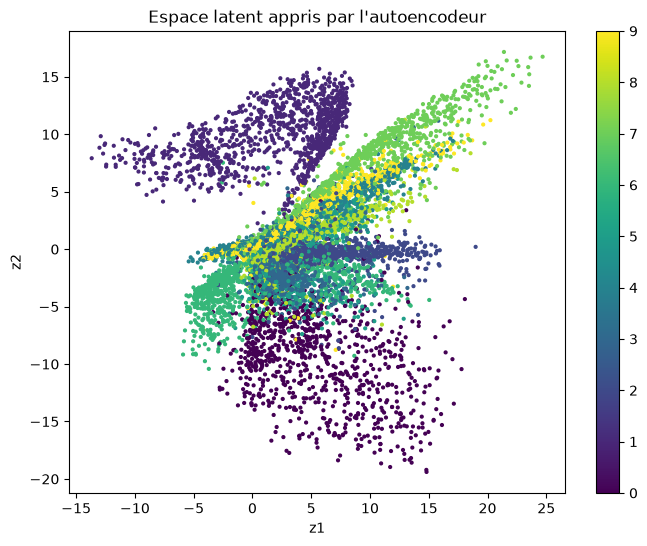

In [14]:
## Visualisation de l'espace latent
ae.eval()

zs = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        z = ae.encode(x)

        zs.append(z.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4)
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par l'autoencodeur")
plt.colorbar(scatter)
afficher("03_ae_latent.png")

Le vecteur latent moyen des images d’un chiffre connu permet de reconstruire un exemple représentatif. Cela ne garantit pas que des points latents choisis au hasard donnent des chiffres valides.

In [15]:
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def generer_chiffre(model, dataloader, chiffre):
    if chiffre not in range(10):
        raise ValueError("Le chiffre doit être compris entre 0 et 9.")

    device = next(model.parameters()).device
    model.eval()

    somme_z = None
    nombre = 0

    for images, labels in dataloader:
        # Sélection des images du chiffre demandé
        images = images[labels == chiffre]

        if images.shape[0] == 0:
            continue

        z = model.encode(images.to(device))

        if somme_z is None:
            somme_z = z.sum(dim=0, keepdim=True)
        else:
            somme_z += z.sum(dim=0, keepdim=True)

        nombre += z.shape[0]

    if nombre == 0:
        raise ValueError(f"Aucune image du chiffre {chiffre} trouvée.")

    z_moyen = somme_z / nombre
    return model.decode(z_moyen).cpu()

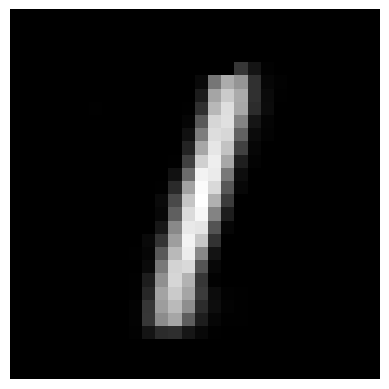

In [16]:
# model : ton autoencodeur entraîné
# train_loader : ton DataLoader MNIST
image = generer_chiffre(ae, train_loader, chiffre=1)

plt.imshow(image[0, 0].numpy(), cmap="gray")
plt.axis("off")
afficher("04_ae_chiffre.png")

## 4. Autoencodeur variationnel (VAE)
Le VAE apprend une moyenne et une log-variance pour chaque image. Il tire un vecteur latent avec la formule `z = mu + std * eps`, ce qui permet de conserver la rétropropagation. Le décodeur reconstruit ensuite l’image.

In [17]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

vae = VAE(latent_dim=2).to(device)
vae

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

La perte combine une erreur de reconstruction BCE et une divergence KL qui rapproche la distribution latente de la loi normale standard.

In [18]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(
        x_hat,
        x,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return rec_loss + beta * kl_loss, rec_loss, kl_loss

In [19]:
## Entrainement
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
def train_vae(model, loader, epochs=20, beta=1.0):
    model.train()

    for epoch in range(epochs):
        total_loss = 0
        total_rec = 0
        total_kl = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat, mu, logvar = model(x)

            loss, rec, kl = vae_loss(
                x_hat,
                x,
                mu,
                logvar,
                beta=beta
            )

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()

        n = len(loader.dataset)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss={total_loss/n:.2f} | "
            f"Rec={total_rec/n:.2f} | "
            f"KL={total_kl/n:.2f}"
        )

train_vae(vae, train_loader, epochs=20)

Epoch 1/20 | Loss=193.81 | Rec=189.81 | KL=4.00
Epoch 2/20 | Loss=168.00 | Rec=163.07 | KL=4.93
Epoch 3/20 | Loss=162.59 | Rec=157.42 | KL=5.17
Epoch 4/20 | Loss=159.14 | Rec=153.77 | KL=5.37
Epoch 5/20 | Loss=156.63 | Rec=151.09 | KL=5.54
Epoch 6/20 | Loss=154.61 | Rec=148.92 | KL=5.69
Epoch 7/20 | Loss=152.81 | Rec=146.98 | KL=5.83
Epoch 8/20 | Loss=151.25 | Rec=145.32 | KL=5.93
Epoch 9/20 | Loss=149.94 | Rec=143.91 | KL=6.03
Epoch 10/20 | Loss=148.83 | Rec=142.73 | KL=6.10
Epoch 11/20 | Loss=147.94 | Rec=141.79 | KL=6.14
Epoch 12/20 | Loss=147.14 | Rec=140.96 | KL=6.18
Epoch 13/20 | Loss=146.53 | Rec=140.29 | KL=6.23
Epoch 14/20 | Loss=145.89 | Rec=139.63 | KL=6.27
Epoch 15/20 | Loss=145.40 | Rec=139.12 | KL=6.28
Epoch 16/20 | Loss=145.04 | Rec=138.70 | KL=6.34
Epoch 17/20 | Loss=144.60 | Rec=138.25 | KL=6.35
Epoch 18/20 | Loss=144.19 | Rec=137.82 | KL=6.37
Epoch 19/20 | Loss=143.80 | Rec=137.41 | KL=6.39
Epoch 20/20 | Loss=143.46 | Rec=137.04 | KL=6.42


In [20]:
@torch.no_grad()
def evaluer_vae(model, loader):
    model.eval()
    totaux = np.zeros(3)
    n = 0
    for x, _ in loader:
        x = x.to(device)
        x_hat, mu, logvar = model(x)
        totaux += [v.item() for v in vae_loss(x_hat, x, mu, logvar)]
        n += x.size(0)
    return totaux / n

loss, rec, kl = evaluer_vae(vae, test_loader)
print(f"Test : Loss={loss:.2f} | Rec={rec:.2f} | KL={kl:.2f}")

Test : Loss=144.63 | Rec=138.19 | KL=6.44


### Reconstruction, espace latent et génération
On observe les reconstructions, puis les moyennes latentes des images de test. Ensuite, on génère des chiffres sans image d’entrée en tirant 20 vecteurs dans une loi normale. Une grille de points latents montre les transitions entre les images.

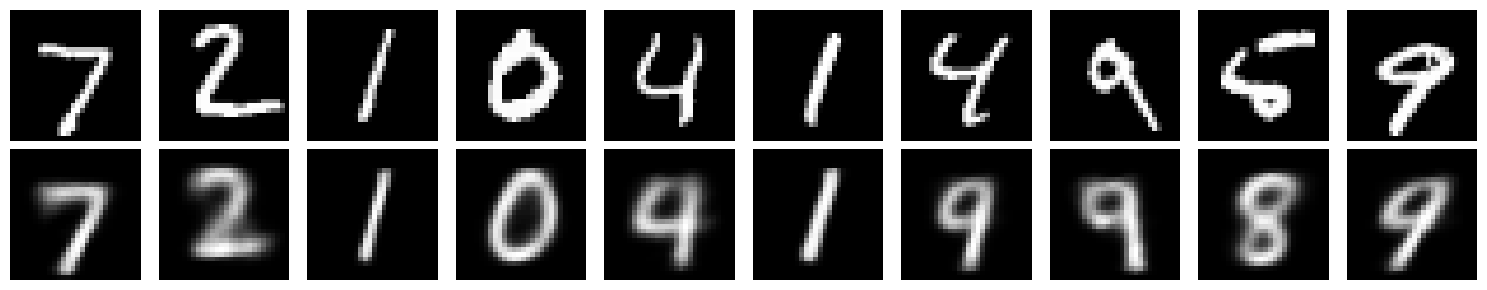

In [21]:
vae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("VAE")

plt.tight_layout()
afficher("05_vae_reconstruction.png")

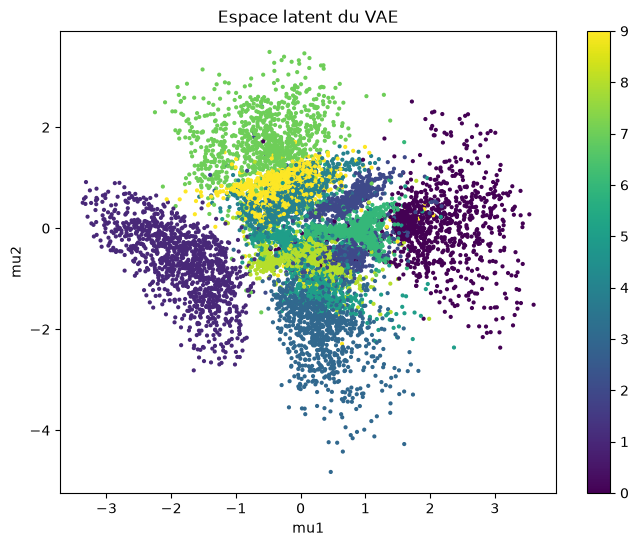

In [22]:
vae.eval()

mus = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        mu, logvar = vae.encode(x)

        mus.append(mu.cpu())
        ys.append(y)

MU = torch.cat(mus).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    MU[:, 0],
    MU[:, 1],
    c=Y,
    s=4
)

plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Espace latent du VAE")
plt.colorbar(scatter)
afficher("06_vae_latent.png")

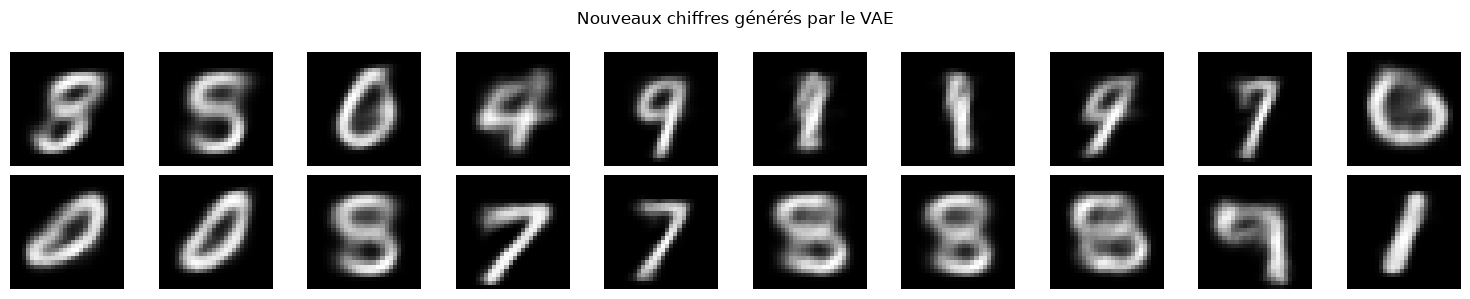

In [23]:
# Générer de nouvelles images
vae.eval()

with torch.no_grad():
    z = torch.randn(20, 2).to(device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("Nouveaux chiffres générés par le VAE")
plt.tight_layout()
afficher("07_vae_generation.png")

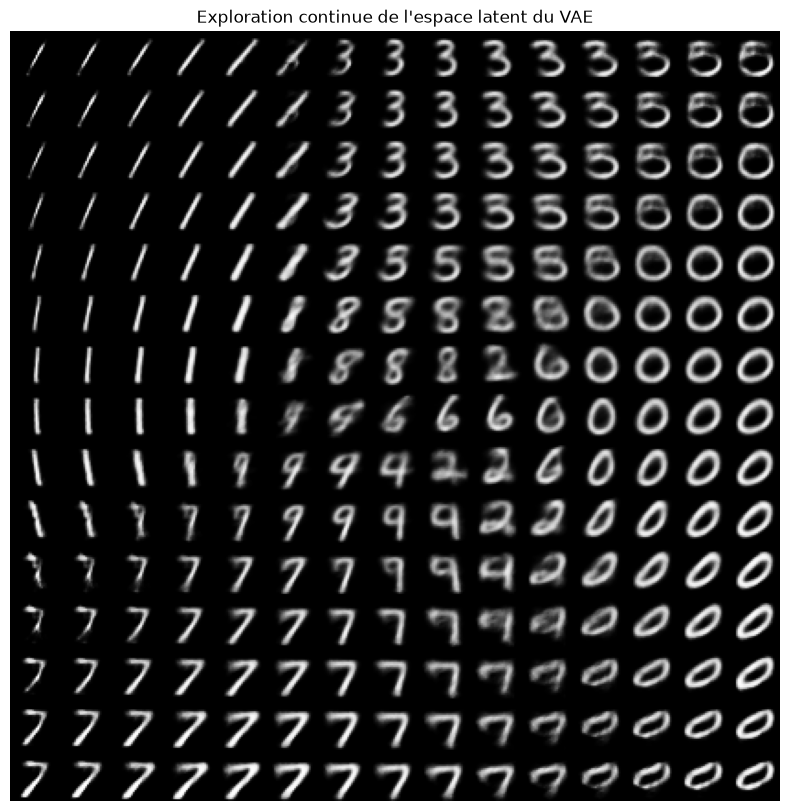

In [24]:
vae.eval()

grid_x = np.linspace(-3, 3, 15)
grid_y = np.linspace(-3, 3, 15)

figure = np.zeros((28 * 15, 28 * 15))

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):

            z = torch.tensor(
                [[xi, yi]],
                dtype=torch.float32,
                device=device
            )

            x_hat = vae.decode(z)
            digit = x_hat.cpu().numpy()[0, 0]

            figure[
                i*28:(i+1)*28,
                j*28:(j+1)*28
            ] = digit

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="gray")
plt.axis("off")
plt.title("Exploration continue de l'espace latent du VAE")
afficher("08_vae_grille.png")

## Conclusion
Le classifieur prédit une classe, l’autoencodeur reconstruit une image et le VAE permet aussi de générer de nouvelles images. Les pertes MSE et BCE + KL ne sont pas directement comparables. Les métriques de test sont calculées par les cellules d’évaluation.